

## Task 1: Lowercasing Basics and Its Drawbacks




In [2]:
#  Part 1


corpus = [
    "Apple released a new product today.",
    "I ate an apple after lunch.",
    "APPLE is one of the biggest technology companies.",
    "The US announced a new policy.",
    "The students helped us complete the project.",
    "US universities offer many research opportunities.",
    "I like Apple products.",
    "She bought an apple from the market.",
    "We visited the US last summer.",
    "The teacher asked us to submit the assignment."
]

print("Number of sentences:", len(corpus))

for i, sentence in enumerate(corpus, 1):
    print(f"{i}. {sentence}")

Number of sentences: 10
1. Apple released a new product today.
2. I ate an apple after lunch.
3. APPLE is one of the biggest technology companies.
4. The US announced a new policy.
5. The students helped us complete the project.
6. US universities offer many research opportunities.
7. I like Apple products.
8. She bought an apple from the market.
9. We visited the US last summer.
10. The teacher asked us to submit the assignment.


#  Part 2
# Comparing vocabulary before and after lowercasing

In [4]:


import re

def tokenize(text):
    return re.findall(r"\b[\w']+\b", text)

# Original vocabulary
original_tokens = []

for sentence in corpus:
    original_tokens.extend(tokenize(sentence))

original_vocabulary = set(original_tokens)

# Lowercase corpus
lowercase_corpus = [sentence.lower() for sentence in corpus]

# Lowercase vocabulary
lowercase_tokens = []

for sentence in lowercase_corpus:
    lowercase_tokens.extend(tokenize(sentence))

lowercase_vocabulary = set(lowercase_tokens)

print("Vocabulary size before lowercasing:", len(original_vocabulary))
print("Vocabulary size after lowercasing:", len(lowercase_vocabulary))

print("\nWords affected by lowercasing:")
for word in sorted(original_vocabulary):
    if word.lower() in original_vocabulary and word != word.lower():
        print(word, "->", word.lower())

Vocabulary size before lowercasing: 49
Vocabulary size after lowercasing: 45

Words affected by lowercasing:
APPLE -> apple
Apple -> apple
The -> the
US -> us


#  Part 3
# Examples where lowercasing changes or removes useful information

In [6]:

ambiguous_examples = [
    ("US", "us", "US = United States, us = a pronoun"),
    ("Apple", "apple", "Apple = company, apple = fruit"),
    ("May", "may", "May = month, may = modal verb")
]    

for original, lowercase, explanation in ambiguous_examples:
    print(f"{original} -> {lowercase}")
    print("Meaning:", explanation)
    print()

US -> us
Meaning: US = United States, us = a pronoun

Apple -> apple
Meaning: Apple = company, apple = fruit

May -> may
Meaning: May = month, may = modal verb



###  Part 4: Effect of Lowercasing on NLP Tasks

Lowercasing can reduce vocabulary size and make text processing easier, but it can also remove important information. In Named Entity Recognition (NER), words such as "Apple" and "US" may provide useful clues that they are proper nouns or named entities. In sentiment analysis, lowercasing can sometimes remove emphasis represented through capitalization, such as "GOOD" versus "good". In search systems, lowercasing can improve matching between words with different capitalization, but it may also create ambiguity between terms such as "US" and "us". Therefore, lowercasing should be applied carefully depending on the NLP task.

# Task 2 — Noise Removal Pipeline

In [9]:
   
# Task 2 - Part 1
# Creating a noisy dataset

noisy_data = [
    "I love this movie! 😊 Visit https://example.com for more info.",
    "@user This product is amazing!!! #awesome",
    "<p>This is a great review.</p> 😊",
    "The service was terrible!!!   http://test.com",
    "@customer I really liked it. #recommended",
    "Amazing product!!! 😍😍 Check www.example.com",
    "<div>Excellent quality and fast delivery.</div>",
    "I don't like this product... 😡 #bad",
    "@shop The package arrived late!!!",
    "This movie was AWESOME!!! 🎬 https://movie.com",
    "<html><body>Very useful product.</body></html>",
    "I paid $100 for this!!! 💰",
    "C++ is a useful programming language. #Programming",
    "@developer Check https://github.com for code.",
    "The website is slow...     but the service is good."
]

print("Number of entries:", len(noisy_data))

for i, text in enumerate(noisy_data, 1):
    print(f"{i}. {text}")

Number of entries: 15
1. I love this movie! 😊 Visit https://example.com for more info.
2. @user This product is amazing!!! #awesome
3. <p>This is a great review.</p> 😊
4. The service was terrible!!!   http://test.com
5. @customer I really liked it. #recommended
6. Amazing product!!! 😍😍 Check www.example.com
7. <div>Excellent quality and fast delivery.</div>
8. I don't like this product... 😡 #bad
9. @shop The package arrived late!!!
10. This movie was AWESOME!!! 🎬 https://movie.com
11. <html><body>Very useful product.</body></html>
12. I paid $100 for this!!! 💰
13. C++ is a useful programming language. #Programming
14. @developer Check https://github.com for code.
15. The website is slow...     but the service is good.


In [10]:
# Task 2 - Part 2

import re

# Remove URLs
def remove_urls(text):
    return re.sub(r"https?://\S+|www\.\S+", "", text)


# Remove HTML tags
def remove_html(text):
    return re.sub(r"<[^>]+>", "", text)


# Remove @mentions
def remove_mentions(text):
    return re.sub(r"@\w+", "", text)


# Remove hashtags but keep the hashtag word
def handle_hashtags(text):
    return re.sub(r"#(\w+)", r"\1", text)


# Remove punctuation
def remove_punctuation(text):
    return re.sub(r"[^\w\s]", "", text)


# Remove extra whitespace
def remove_extra_whitespace(text):
    return re.sub(r"\s+", " ", text).strip()


print("Regex functions created successfully.")

Regex functions created successfully.


In [11]:
sample = noisy_data[0]

print("Original:")
print(sample)

print("\nAfter URL removal:")
print(remove_urls(sample))

print("\nAfter HTML removal:")
print(remove_html(sample))

print("\nAfter mention removal:")
print(remove_mentions("@user Hello everyone"))

print("\nAfter hashtag handling:")
print(handle_hashtags("#awesome product"))

print("\nAfter punctuation removal:")
print(remove_punctuation("Hello!!! How are you?"))

print("\nAfter whitespace removal:")
print(remove_extra_whitespace("Hello     world   NLP"))

Original:
I love this movie! 😊 Visit https://example.com for more info.

After URL removal:
I love this movie! 😊 Visit  for more info.

After HTML removal:
I love this movie! 😊 Visit https://example.com for more info.

After mention removal:
 Hello everyone

After hashtag handling:
awesome product

After punctuation removal:
Hello How are you

After whitespace removal:
Hello world NLP


In [12]:
# Task 2 - Part 3

def clean_text(text):
    text = remove_urls(text)
    text = remove_html(text)
    text = remove_mentions(text)
    text = handle_hashtags(text)
    text = remove_punctuation(text)
    text = remove_extra_whitespace(text)
    
    return text


cleaned_data = [clean_text(text) for text in noisy_data]

for i, (original, cleaned) in enumerate(zip(noisy_data, cleaned_data), 1):
    print(f"{i}.")
    print("Before:", original)
    print("After :", cleaned)
    print()

1.
Before: I love this movie! 😊 Visit https://example.com for more info.
After : I love this movie Visit for more info

2.
Before: @user This product is amazing!!! #awesome
After : This product is amazing awesome

3.
Before: <p>This is a great review.</p> 😊
After : This is a great review

4.
Before: The service was terrible!!!   http://test.com
After : The service was terrible

5.
Before: @customer I really liked it. #recommended
After : I really liked it recommended

6.
Before: Amazing product!!! 😍😍 Check www.example.com
After : Amazing product Check

7.
Before: <div>Excellent quality and fast delivery.</div>
After : Excellent quality and fast delivery

8.
Before: I don't like this product... 😡 #bad
After : I dont like this product bad

9.
Before: @shop The package arrived late!!!
After : The package arrived late

10.
Before: This movie was AWESOME!!! 🎬 https://movie.com
After : This movie was AWESOME

11.
Before: <html><body>Very useful product.</body></html>
After : Very useful prod

In [13]:
# Testing a different order of operations

def clean_text_different_order(text):
    text = remove_punctuation(text)
    text = remove_urls(text)
    text = remove_html(text)
    text = remove_mentions(text)
    text = handle_hashtags(text)
    text = remove_extra_whitespace(text)
    
    return text


sample = "Check https://example.com!!! #NLP @user"

print("Original:")
print(sample)

print("\nNormal order:")
print(clean_text(sample))

print("\nDifferent order:")
print(clean_text_different_order(sample))

Original:
Check https://example.com!!! #NLP @user

Normal order:
Check NLP

Different order:
Check httpsexamplecom NLP user


### Observation

Changing the order of preprocessing steps can sometimes change the output. For example, if punctuation is removed before URL removal, characters inside URLs may be modified and the URL pattern may no longer be detected correctly. Therefore, URL and HTML removal should generally be performed before aggressive punctuation removal.

In [15]:
# Task 2 - Part 4

import pandas as pd

examples = noisy_data[:5]

comparison = pd.DataFrame({
    "Before Cleaning": examples,
    "After Cleaning": [clean_text(text) for text in examples]
})

comparison

,Before Cleaning,After Cleaning
0,I love this movie! 😊 Visit https://example.com...,I love this movie Visit for more info
1,@user This product is amazing!!! #awesome,This product is amazing awesome
2,<p>This is a great review.</p> 😊,This is a great review
3,The service was terrible!!! http://test.com,The service was terrible
4,@customer I really liked it. #recommended,I really liked it recommended


### Over-cleaning Observation

Aggressive punctuation removal can damage useful information. For example, "C++" may become "C", "$100" may become "100", and an email address may lose its structure. Therefore, preprocessing rules should depend on the NLP application and should not remove every special character blindly.

# Task 3 — Stop-Word Removal and Its Effect on Vocabulary

In [18]:
# Task 3 - Setup

import nltk
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Download required NLTK resources
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

[nltk_data] Downloading package stopwords to C:\Users\rida-
[nltk_data]     fatima\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\rida-
[nltk_data]     fatima\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\rida-
[nltk_data]     fatima\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


 ### Part 1 — Load stop-word list

In [20]:
# Task 3 - Part 1

english_stopwords = set(stopwords.words("english"))

print("Total number of English stop-words:", len(english_stopwords))

print("\nFirst 20 stop-words:")
print(list(english_stopwords)[:20])

Total number of English stop-words: 198

First 20 stop-words:
['and', 'don', 'very', "mightn't", 'hadn', 'why', 'on', 'from', "shan't", 'themselves', 'up', 'about', "you're", "wouldn't", "he'll", 'y', "you'd", 'here', "she'd", 've']


 ### Part 2 — Dataset and comparison

In [22]:
# Task 3 - Part 2
# Small movie-review dataset

reviews = [
    "This movie was very good and I really enjoyed it.",
    "The acting was excellent and the story was interesting.",
    "I did not like this movie because it was too slow.",
    "The movie was boring and the characters were weak.",
    "I loved the beautiful story and amazing acting.",
    "This film was not good and I would not recommend it.",
    "The actors performed very well in this movie.",
    "I enjoyed every minute of this wonderful film.",
    "The story was simple but the movie was entertaining.",
    "This was one of the best movies I have watched.",
    "The movie was terrible and completely disappointing.",
    "I really liked the characters and the story.",
    "The film was exciting and full of action.",
    "I did not enjoy the ending of this movie.",
    "This movie was fantastic and very enjoyable."
]

def tokenize_text(text):
    return word_tokenize(text.lower())

# Tokens before removal
tokens_before = []

for review in reviews:
    tokens_before.extend(tokenize_text(review))

# Tokens after stop-word removal
tokens_after = [
    token for token in tokens_before
    if token.isalpha() and token not in english_stopwords
]

vocab_before = set(tokens_before)
vocab_after = set(tokens_after)

average_before = sum(
    len(tokenize_text(review)) for review in reviews
) / len(reviews)

average_after = sum(
    len([
        token for token in tokenize_text(review)
        if token.isalpha() and token not in english_stopwords
    ])
    for review in reviews
) / len(reviews)

statistics = pd.DataFrame({
    "Measure": [
        "Total Tokens",
        "Vocabulary Size",
        "Average Sentence Length"
    ],
    "Before Stop-word Removal": [
        len(tokens_before),
        len(vocab_before),
        average_before
    ],
    "After Stop-word Removal": [
        len(tokens_after),
        len(vocab_after),
        average_after
    ]
})

statistics

,Measure,Before Stop-word Removal,After Stop-word Removal
0,Total Tokens,147.0,59.000000
1,Vocabulary Size,59.0,42.000000
2,Average Sentence Length,9.8,3.933333


 ### Part 3 — Top 15 words before removal

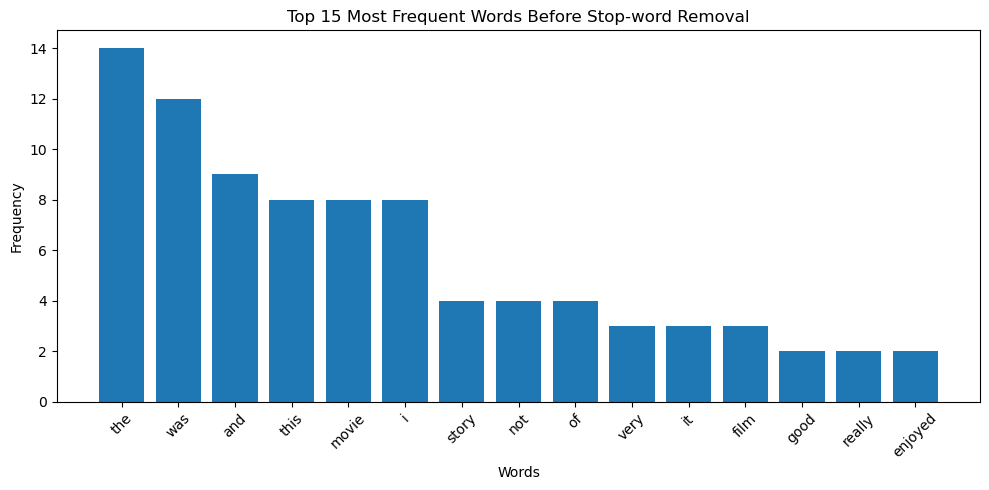

In [24]:


frequency_before = Counter(
    token for token in tokens_before
    if token.isalpha()
)

top15_before = frequency_before.most_common(15)

words_before = [item[0] for item in top15_before]
counts_before = [item[1] for item in top15_before]

plt.figure(figsize=(10, 5))
plt.bar(words_before, counts_before)
plt.title("Top 15 Most Frequent Words Before Stop-word Removal")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

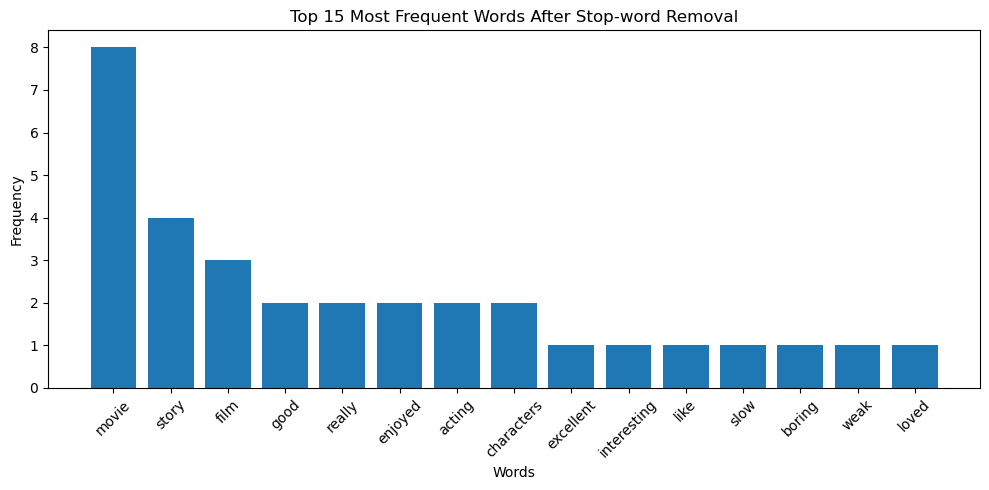

In [25]:
# Top 15 words after stop-word removal

frequency_after = Counter(tokens_after)

top15_after = frequency_after.most_common(15)

words_after = [item[0] for item in top15_after]
counts_after = [item[1] for item in top15_after]

plt.figure(figsize=(10, 5))
plt.bar(words_after, counts_after)
plt.title("Top 15 Most Frequent Words After Stop-word Removal")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### PART 4 : Creating a custom stop-word list

In [27]:


custom_stopwords = english_stopwords.copy()

domain_specific_words = {
    "movie",
    "film",
    "story",
    "acting",
    "actor",
    "actors",
    "characters",
    "watch",
    "watched",
    "really"
}

custom_stopwords.update(domain_specific_words)

print("Original stop-word count:", len(english_stopwords))
print("Custom stop-word count:", len(custom_stopwords))

print("\nAdded domain-specific words:")
for word in sorted(domain_specific_words):
    print(word)

Original stop-word count: 198
Custom stop-word count: 208

Added domain-specific words:
acting
actor
actors
characters
film
movie
really
story
watch
watched


### Observation

Stop-word removal reduces the number of tokens and usually reduces vocabulary size. It can make the remaining text more focused on content-bearing words. However, some stop-words can carry important meaning, especially negation words such as "not" and "never". Therefore, stop-word removal should be performed according to the requirements of the NLP task.

 # Task 4 — Risks of Stop-Word Removal

### Part 1 — Sentiment and negation

In [31]:


sentiment_sentences = [
    "This movie is not good.",
    "I am never happy with this service.",
    "There is no problem with the product.",
    "This is not an amazing movie.",
    "I do not like this product."
]

def remove_stopwords(text):
    tokens = word_tokenize(text.lower())
    return [
        word for word in tokens
        if word.isalpha() and word not in english_stopwords
    ]

for sentence in sentiment_sentences:
    original_tokens = word_tokenize(sentence.lower())
    reduced_tokens = remove_stopwords(sentence)
    
    print("Original :", sentence)
    print("Tokens   :", original_tokens)
    print("After stop-word removal:", reduced_tokens)
    print()

Original : This movie is not good.
Tokens   : ['this', 'movie', 'is', 'not', 'good', '.']
After stop-word removal: ['movie', 'good']

Original : I am never happy with this service.
Tokens   : ['i', 'am', 'never', 'happy', 'with', 'this', 'service', '.']
After stop-word removal: ['never', 'happy', 'service']

Original : There is no problem with the product.
Tokens   : ['there', 'is', 'no', 'problem', 'with', 'the', 'product', '.']
After stop-word removal: ['problem', 'product']

Original : This is not an amazing movie.
Tokens   : ['this', 'is', 'not', 'an', 'amazing', 'movie', '.']
After stop-word removal: ['amazing', 'movie']

Original : I do not like this product.
Tokens   : ['i', 'do', 'not', 'like', 'this', 'product', '.']
After stop-word removal: ['like', 'product']



In [32]:
# Checking important negation words

negation_words = {"not", "no", "never", "neither", "nor", "don't", "doesn't", "didn't"}

for sentence in sentiment_sentences:
    tokens = word_tokenize(sentence.lower())
    removed_negations = [
        word for word in tokens
        if word in negation_words and word in english_stopwords
    ]
    
    print("Sentence:", sentence)
    print("Negation words removed:", removed_negations)
    print()

Sentence: This movie is not good.
Negation words removed: ['not']

Sentence: I am never happy with this service.
Negation words removed: []

Sentence: There is no problem with the product.
Negation words removed: ['no']

Sentence: This is not an amazing movie.
Negation words removed: ['not']

Sentence: I do not like this product.
Negation words removed: ['not']



### Observation

Blind stop-word removal can change sentiment because words such as "not", "no", and "never" can be removed. For example, "This movie is not good" may become "movie good", which can incorrectly suggest positive sentiment. Therefore, negation words should usually be preserved in sentiment-analysis preprocessing.

 # Part 2 — Machine Translation

In [35]:
# Task 4 - Part 2

translation_sentences = [
    "I do not like this movie.",
    "She is not going to the market.",
    "He never drinks coffee."
]

translation_data = []

for sentence in translation_sentences:
    reduced = " ".join(remove_stopwords(sentence))
    
    translation_data.append({
        "Original English": sentence,
        "Reduced English": reduced
    })

translation_df = pd.DataFrame(translation_data)

translation_df

,Original English,Reduced English
0,I do not like this movie.,like movie
1,She is not going to the market.,going market
2,He never drinks coffee.,never drinks coffee


In [36]:
# Enter the Urdu translations obtained from Google Translate

translation_df["Original Urdu Translation"] = [
    "مجھے یہ فلم پسند نہیں ہے۔",
    "وہ بازار نہیں جا رہی ہے۔",
    "وہ کبھی کافی نہیں پیتا۔"
]

translation_df["Reduced Urdu Translation"] = [
    "مجھے یہ فلم پسند ہے۔",
    "وہ بازار جا رہی ہے۔",
    "وہ کافی پیتا ہے۔"
]

translation_df

,Original English,Reduced English,Original Urdu Translation,Reduced Urdu Translation
0,I do not like this movie.,like movie,مجھے یہ فلم پسند نہیں ہے۔,مجھے یہ فلم پسند ہے۔
1,She is not going to the market.,going market,وہ بازار نہیں جا رہی ہے۔,وہ بازار جا رہی ہے۔
2,He never drinks coffee.,never drinks coffee,وہ کبھی کافی نہیں پیتا۔,وہ کافی پیتا ہے۔


### Observation

Removing stop-words before machine translation can distort the meaning because grammatical words often carry important information. In particular, removing negation can reverse the meaning of a sentence. Therefore, the original sentence should normally be translated instead of translating text after blind stop-word removal.

# Part 3 — Chatbot Intent

In [39]:


chatbot_queries = [
    "How to not be charged?",
    "What is the status of my order?",
    "I do not want to cancel my order.",
    "Can I get a refund?",
    "Why has my order not arrived?"
]

for query in chatbot_queries:
    reduced = " ".join(remove_stopwords(query))
    
    print("Original :", query)
    print("Reduced  :", reduced)
    print()

Original : How to not be charged?
Reduced  : charged

Original : What is the status of my order?
Reduced  : status order

Original : I do not want to cancel my order.
Reduced  : want cancel order

Original : Can I get a refund?
Reduced  : get refund

Original : Why has my order not arrived?
Reduced  : order arrived



In [40]:
# Expected intent before and possible interpretation after stop-word removal

chatbot_results = pd.DataFrame({
    "Original Query": chatbot_queries,
    "After Stop-word Removal": [
        "charged",
        "status order",
        "want cancel order",
        "get refund",
        "order arrived"
    ],
    "Original Intent": [
        "Avoid being charged",
        "Check order status",
        "Do not cancel order",
        "Request refund",
        "Order has not arrived"
    ],
    "Possible Damaged Intent": [
        "Charging/payment issue",
        "General order information",
        "Cancel order",
        "Refund information",
        "Order arrival information"
    ]
})

chatbot_results

,Original Query,After Stop-word Removal,Original Intent,Possible Damaged Intent
0,How to not be charged?,charged,Avoid being charged,Charging/payment issue
1,What is the status of my order?,status order,Check order status,General order information
2,I do not want to cancel my order.,want cancel order,Do not cancel order,Cancel order
3,Can I get a refund?,get refund,Request refund,Refund information
4,Why has my order not arrived?,order arrived,Order has not arrived,Order arrival information


### Observation

Stop-word removal can damage chatbot intent because grammatical words can distinguish between different requests. For example, "I do not want to cancel my order" contains a negation that changes the meaning of "cancel my order". If "do not" is removed, the query may incorrectly be interpreted as a request to cancel the order.

In [42]:


important_negations = {
    "not",
    "no",
    "never",
    "neither",
    "nor",
    "don't",
    "doesn't",
    "didn't",
    "isn't",
    "aren't",
    "wasn't",
    "weren't",
    "cannot",
    "can't",
    "won't"
}

safe_stopwords = english_stopwords - important_negations

print("Original stop-word count:", len(english_stopwords))
print("Safe stop-word count:", len(safe_stopwords))

print("\nNegation words preserved:")
print(sorted(important_negations))     

Original stop-word count: 198
Safe stop-word count: 187

Negation words preserved:
["aren't", "can't", 'cannot', "didn't", "doesn't", "don't", "isn't", 'neither', 'never', 'no', 'nor', 'not', "wasn't", "weren't", "won't"]


In [43]:
def safe_remove_stopwords(text):
    tokens = word_tokenize(text.lower())
    
    return [
        word for word in tokens
        if word.isalpha() and word not in safe_stopwords
    ]


for sentence in sentiment_sentences:
    normal = remove_stopwords(sentence)
    safe = safe_remove_stopwords(sentence)
    
    print("Original:", sentence)
    print("Normal removal:", normal)
    print("Safe removal:", safe)
    print()

Original: This movie is not good.
Normal removal: ['movie', 'good']
Safe removal: ['movie', 'not', 'good']

Original: I am never happy with this service.
Normal removal: ['never', 'happy', 'service']
Safe removal: ['never', 'happy', 'service']

Original: There is no problem with the product.
Normal removal: ['problem', 'product']
Safe removal: ['no', 'problem', 'product']

Original: This is not an amazing movie.
Normal removal: ['amazing', 'movie']
Safe removal: ['not', 'amazing', 'movie']

Original: I do not like this product.
Normal removal: ['like', 'product']
Safe removal: ['not', 'like', 'product']



### Final Observation

A safer stop-word strategy is to remove common grammatical words while keeping important negation words such as "not", "no", and "never". This preserves information that can affect sentiment, translation, and chatbot intent. The safe strategy performs better for sentences where negation changes the meaning.

 # Task 5 — Hands-On with the Porter Stemmer

# Part 1 — Create 30+ words and stem them

In [47]:
# Task 5 - Part 1

from nltk.stem import PorterStemmer, SnowballStemmer

porter = PorterStemmer()
snowball = SnowballStemmer("english")

words = [
    "running",
    "runs",
    "runner",
    "studies",
    "studying",
    "study",
    "happily",
    "happiness",
    "generalization",
    "generalized",
    "general",
    "better",
    "best",
    "was",
    "walking",
    "walked",
    "walks",
    "playing",
    "played",
    "player",
    "connection",
    "connected",
    "connecting",
    "organization",
    "organized",
    "organizational",
    "relational",
    "relations",
    "relate",
    "universities",
    "university",
    "universe",
    "computing",
    "computer",
    "computation"
]

porter_results = []

for word in words:
    stem = porter.stem(word)
    
    porter_results.append({
        "Word": word,
        "Stem": stem
    })

porter_df = pd.DataFrame(porter_results)

porter_df

,Word,Stem
0,running,run
1,runs,run
2,runner,runner
3,studies,studi
4,studying,studi
5,study,studi
6,happily,happili
7,happiness,happi
8,generalization,gener
9,generalized,gener


# part 2

In [49]:


correctness = []

for word in words:
    stem = porter.stem(word)
    
    # Simple manual judgment for demonstration
    if word in ["running", "runs", "runner", "walking", "walked", "walks",
                "playing", "played", "player", "studies", "studying"]:
        judgment = "Correct"
    else:
        judgment = "Check manually"
    
    correctness.append({
        "Word": word,
        "Stem": stem,
        "Correct/Incorrect": judgment
    })

porter_correctness_df = pd.DataFrame(correctness)

porter_correctness_df

,Word,Stem,Correct/Incorrect
0,running,run,Correct
1,runs,run,Correct
2,runner,runner,Correct
3,studies,studi,Correct
4,studying,studi,Correct
5,study,studi,Check manually
6,happily,happili,Check manually
7,happiness,happi,Check manually
8,generalization,gener,Check manually
9,generalized,gener,Check manually


# Part 3 — Over-stemming examples

In [51]:


over_stemming_pairs = [
    ("university", "universe"),
    ("relational", "relation"),
    ("organization", "organ")
]

for word1, word2 in over_stemming_pairs:
    stem1 = porter.stem(word1)
    stem2 = porter.stem(word2)
    
    print(f"{word1} -> {stem1}")
    print(f"{word2} -> {stem2}")
    print("Same stem:", stem1 == stem2)
    print()

university -> univers
universe -> univers
Same stem: True

relational -> relat
relation -> relat
Same stem: True

organization -> organ
organ -> organ
Same stem: True



In [52]:
# Under-stemming examples

under_stemming_pairs = [
    ("studies", "study"),
    ("university", "universities"),
    ("connection", "connect")
]

for word1, word2 in under_stemming_pairs:
    stem1 = porter.stem(word1)
    stem2 = porter.stem(word2)
    
    print(f"{word1} -> {stem1}")
    print(f"{word2} -> {stem2}")
    print("Same stem:", stem1 == stem2)
    print()

studies -> studi
study -> studi
Same stem: True

university -> univers
universities -> univers
Same stem: True

connection -> connect
connect -> connect
Same stem: True



### Explanation

**Over-stemming** occurs when words that have different meanings are reduced to the same stem.

**Under-stemming** occurs when words that are related in meaning are reduced to different stems.

Stemming is rule-based and does not necessarily produce a valid English word. Its purpose is to reduce related word forms rather than produce a dictionary-quality base word.

# Part 4 — Porter vs Snowball

In [55]:


comparison_results = []

for word in words:
    porter_stem = porter.stem(word)
    snowball_stem = snowball.stem(word)
    
    comparison_results.append({
        "Word": word,
        "Porter Stem": porter_stem,
        "Snowball Stem": snowball_stem,
        "Different?": porter_stem != snowball_stem
    })

stemmer_comparison = pd.DataFrame(comparison_results)

stemmer_comparison

,Word,Porter Stem,Snowball Stem,Different?
0,running,run,run,False
1,runs,run,run,False
2,runner,runner,runner,False
3,studies,studi,studi,False
4,studying,studi,studi,False
5,study,studi,studi,False
6,happily,happili,happili,False
7,happiness,happi,happi,False
8,generalization,gener,general,True
9,generalized,gener,general,True


In [56]:
# Words where Porter and Snowball produce different results

different_results = stemmer_comparison[
    stemmer_comparison["Different?"] == True
]

different_results

,Word,Porter Stem,Snowball Stem,Different?
8,generalization,gener,general,True
9,generalized,gener,general,True
10,general,gener,general,True
13,was,wa,was,True


# Task 6 — Lemmatization (spaCy) vs Stemming

In [58]:
# Task 6 - Setup

import spacy
import time

nlp = spacy.load("en_core_web_sm")

print("spaCy model loaded successfully.")

spaCy model loaded successfully.


In [59]:
# Task 6 - Part 1

paragraph = """
Natural language processing allows computers to understand and process human language.
Language contains many different forms of words that can make text processing difficult.
For example, a person may write that they are running, while another person may write that
they ran yesterday or that they will run tomorrow. Stemming attempts to reduce these words
to a common form by removing prefixes or suffixes according to linguistic rules. However,
the resulting stem may not always be a real English word. Lemmatization takes a different
approach because it attempts to find the dictionary form of a word. It also uses information
such as the part of speech of the word. For example, better can be converted to good and was
can be converted to be when the context and part of speech are correctly identified.
Lemmatization is generally more linguistically meaningful than simple stemming, although it
can require more computational resources. Both methods are useful in natural language
processing applications such as search engines, text classification, information retrieval,
sentiment analysis, and document processing. The appropriate method depends on the goal of
the application and the required balance between speed and linguistic accuracy.
"""

print("Number of words:", len(paragraph.split()))

assert len(paragraph.split()) >= 100

Number of words: 191


In [60]:
# Process paragraph with spaCy

doc = nlp(paragraph)

spacy_results = []

for token in doc:
    if token.is_alpha:
        spacy_results.append({
            "Token": token.text,
            "POS": token.pos_,
            "Lemma": token.lemma_
        })

spacy_df = pd.DataFrame(spacy_results)

spacy_df.head(30)

,Token,POS,Lemma
0,Natural,ADJ,natural
1,language,NOUN,language
2,processing,NOUN,processing
3,allows,VERB,allow
4,computers,NOUN,computer
5,to,PART,to
6,understand,VERB,understand
7,and,CCONJ,and
8,process,VERB,process
9,human,ADJ,human


# part 2: add porter stems

In [62]:
# Task 6 - Part 2

comparison = []

for token in doc:
    if token.is_alpha:
        comparison.append({
            "Token": token.text,
            "POS": token.pos_,
            "Stem": porter.stem(token.text),
            "Lemma": token.lemma_
        })

comparison_df = pd.DataFrame(comparison)

comparison_df.head(50)

,Token,POS,Stem,Lemma
0,Natural,ADJ,natur,natural
1,language,NOUN,languag,language
2,processing,NOUN,process,processing
3,allows,VERB,allow,allow
4,computers,NOUN,comput,computer
5,to,PART,to,to
6,understand,VERB,understand,understand
7,and,CCONJ,and,and
8,process,VERB,process,process
9,human,ADJ,human,human


In [63]:


interesting_words = [
    "better",
    "best",
    "was",
    "running",
    "studies",
    "studying"
]

for word in interesting_words:
    word_doc = nlp(word)
    
    for token in word_doc:
             print(
            f"Word: {token.text:10} | "
            f"POS: {token.pos_:8} | "
            f"Stem: {porter.stem(token.text):10} | "
            f"Lemma: {token.lemma_}"
             )

Word: better     | POS: ADV      | Stem: better     | Lemma: well
Word: best       | POS: ADV      | Stem: best       | Lemma: well
Word: was        | POS: AUX      | Stem: wa         | Lemma: be
Word: running    | POS: VERB     | Stem: run        | Lemma: run
Word: studies    | POS: NOUN     | Stem: studi      | Lemma: study
Word: studying   | POS: VERB     | Stem: studi      | Lemma: study


### Role of POS Tags

The POS tag provides grammatical information about a word. This information helps a lemmatizer choose the appropriate dictionary form. For example, the word "better" can be associated with "good" when it is recognized in the appropriate grammatical context, while "was" can be reduced to "be". Stemming does not use this type of grammatical information and instead applies suffix-based rules.

# part 4:measuring execution time

In [66]:


test_words = [token.text for token in doc if token.is_alpha]

# Porter stemming time
start = time.time()

porter_output = [
    porter.stem(word)
    for word in test_words
]

porter_time = time.time() - start


# spaCy lemmatization time
start = time.time()

spacy_doc = nlp(" ".join(test_words))

lemma_output = [
    token.lemma_
    for token in spacy_doc
    if token.is_alpha
]

lemma_time = time.time() - start


print("Porter Stemmer time:", porter_time, "seconds")
print("spaCy Lemmatization time:", lemma_time, "seconds")

Porter Stemmer time: 0.016437053680419922 seconds
spaCy Lemmatization time: 0.055585384368896484 seconds


# Task 7 — Preprocessing Pipeline

# Part 1 — Create configurable preprocessing pipeline

In [69]:
# Task 7 - Part 1

import re
import pandas as pd
import numpy as np

from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer

porter = PorterStemmer()


def preprocess_text(
    text,
    lowercase=True,
    noise_removal=True,
    remove_stopwords=False,
    stemming=False,
    lemmatization=False
):
    # Step 1: Lowercasing
    if lowercase:
        text = text.lower()

    # Step 2: Noise removal
    if noise_removal:
        text = re.sub(r"https?://\S+|www\.\S+", "", text)
        text = re.sub(r"<[^>]+>", "", text)
        text = re.sub(r"@\w+", "", text)
        text = re.sub(r"#(\w+)", r"\1", text)
        text = re.sub(r"[^\w\s]", "", text)
        text = re.sub(r"\s+", " ", text).strip()

    # Step 3: Tokenization
    tokens = word_tokenize(text)

    # Step 4: Stop-word removal
    if remove_stopwords:
        tokens = [
            word for word in tokens
            if word.isalpha() and word not in english_stopwords
        ]

    # Step 5: Stemming
    if stemming:
        tokens = [porter.stem(word) for word in tokens]

    # Step 6: Lemmatization
    if lemmatization:
        doc = nlp(" ".join(tokens))
        tokens = [
            token.lemma_
            for token in doc
            if token.is_alpha
        ]

    return tokens


print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# part 2: create 50+ docs

In [71]:
# Task 7 - Part 2

documents = [
    "The movie was excellent and the acting was amazing.",
    "I really enjoyed this wonderful film.",
    "The story was interesting and entertaining.",
    "The actors performed very well in the movie.",
    "This was one of the best movies I have watched.",
    "The film was fantastic and full of action.",
    "I loved the beautiful story and amazing characters.",
    "This movie was enjoyable and exciting.",
    "The acting was brilliant and the story was excellent.",
    "I would definitely recommend this movie.",
    
    "The movie was boring and disappointing.",
    "I did not enjoy this film at all.",
    "The acting was terrible and the story was weak.",
    "This was one of the worst movies I watched.",
    "The film was slow and extremely boring.",
    "I hated the ending of this movie.",
    "The characters were poorly developed.",
    "This movie was disappointing and badly made.",
    "The story was confusing and boring.",
    "I would not recommend this terrible film.",
    
    "The movie was good and entertaining.",
    "I liked the actors and the story.",
    "The film had excellent performances.",
    "This was a very enjoyable movie.",
    "The story was simple but interesting.",
    "I really liked this film.",
    "The acting was good throughout the movie.",
    "This movie had a great ending.",
    "The characters were interesting and realistic.",
    "I enjoyed watching this film.",
    
    "The movie was bad and boring.",
    "I disliked almost everything about this film.",
    "The acting was poor and unrealistic.",
    "This movie was a complete disappointment.",
    "The story was weak and predictable.",
    "I did not like the characters.",
    "The film was too long and boring.",
    "The ending was terrible.",
    "This was not an enjoyable movie.",
    "I would never recommend this film.",
    
    "The movie was absolutely fantastic.",
    "I enjoyed every part of this film.",
    "The actors gave excellent performances.",
    "The story was creative and exciting.",
    "This was a great movie with wonderful acting.",
    "I loved the characters in this film.",
    "The movie was entertaining from beginning to end.",
    "The film had an excellent story.",
    "I would recommend this movie to everyone.",
    "This was an amazing and enjoyable experience.",
    
    "The movie was extremely disappointing.",
    "I did not like the story or acting.",
    "The film was boring from beginning to end.",
    "The actors gave weak performances.",
    "This movie was not worth watching."
]

print("Number of documents:", len(documents))

Number of documents: 55


# Part 3 — Four configurations


In [73]:


configurations = {
    "Lowercase Only": {
        "lowercase": True,
        "noise_removal": False,
        "remove_stopwords": False,
        "stemming": False,
        "lemmatization": False
    },

    "Lowercase + Stopwords": {
        "lowercase": True,
        "noise_removal": False,
        "remove_stopwords": True,
        "stemming": False,
        "lemmatization": False
    },

    "Lowercase + Stemming": {
        "lowercase": True,
        "noise_removal": False,
        "remove_stopwords": False,
        "stemming": True,
        "lemmatization": False
    },

    "Lowercase + Lemmatization": {
        "lowercase": True,
        "noise_removal": False,
        "remove_stopwords": False,
        "stemming": False,
        "lemmatization": True
    }
}

print("Configurations:")
for name in configurations:
    print("-", name)

Configurations:
- Lowercase Only
- Lowercase + Stopwords
- Lowercase + Stemming
- Lowercase + Lemmatization


# Calculate vocabulary size and average tokens

In [74]:
# Calculate statistics for all configurations

configuration_results = []

for config_name, settings in configurations.items():

    processed_documents = []

    for document in documents:
        tokens = preprocess_text(document, **settings)
        processed_documents.append(tokens)

    all_tokens = []

    for tokens in processed_documents:
        all_tokens.extend(tokens)

    vocabulary_size = len(set(all_tokens))

    average_tokens = np.mean([
        len(tokens)
        for tokens in processed_documents
    ])

    configuration_results.append({
        "Configuration": config_name,
        "Vocabulary Size": vocabulary_size,
        "Average Tokens per Document": round(average_tokens, 2)
    })


configuration_df = pd.DataFrame(configuration_results)

configuration_df

,Configuration,Vocabulary Size,Average Tokens per Document
0,Lowercase Only,100,7.62
1,Lowercase + Stopwords,75,3.35
2,Lowercase + Stemming,92,7.62
3,Lowercase + Lemmatization,91,6.62


# Part 4 — Classification Experiment

In [117]:
# Task 7 - Part 4

labels = (
    [1] * 10 +
    [0] * 10 +
    [1] * 10 +
    [0] * 10 +
    [1] * 10 +
    [0] * 5
)

print("Number of documents:", len(documents))
print("Number of labels:", len(labels))

Number of documents: 55
Number of labels: 55


In [119]:
# Machine Learning imports

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

In [121]:
# TF-IDF + Naive Bayes classification

classification_results = []

for config_name, settings in configurations.items():

    processed_texts = []

    for document in documents:
        tokens = preprocess_text(document, **settings)
        processed_texts.append(" ".join(tokens))

    X_train, X_test, y_train, y_test = train_test_split(
        processed_texts,
        labels,
        test_size=0.25,
        random_state=42,
        stratify=labels
    )

    vectorizer = TfidfVectorizer()

    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    classifier = MultinomialNB()

    classifier.fit(X_train_tfidf, y_train)

    predictions = classifier.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, predictions)

    classification_results.append({
        "Configuration": config_name,
        "Accuracy": round(accuracy, 4)
    })


classification_df = pd.DataFrame(classification_results)

classification_df

,Configuration,Accuracy
0,Lowercase Only,0.8571
1,Lowercase + Stopwords,0.8571
2,Lowercase + Stemming,0.7857
3,Lowercase + Lemmatization,0.7857
